In [2]:
!pip install datasets pillow matplotlib
!pip install --upgrade pillow
import PIL
print(PIL.__version__)

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
12.2.0


In [3]:
from datasets import load_dataset

dataset = load_dataset("simonMadec/VegAnn")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})


In [4]:
sample = dataset["train"][0]

print(sample.keys())

dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


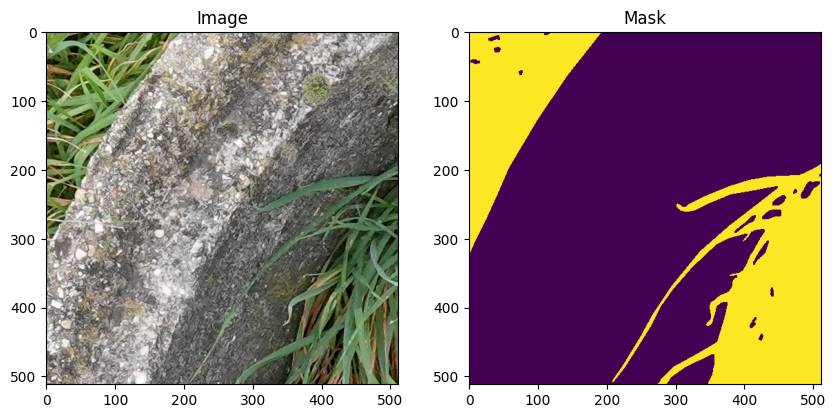

In [5]:
import matplotlib.pyplot as plt

sample = dataset["train"][0]

image = sample["image"]
mask = sample["mask"]

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Image")

plt.subplot(1,2,2)
plt.imshow(mask)
plt.title("Mask")

plt.show()

In [6]:
subset = dataset["train"].select(range(100))

print(len(subset))

100


In [7]:
import os

save_dir = "vegann_subset"

os.makedirs(save_dir, exist_ok=True)

for i in range(100):
    img = subset[i]["image"]
    img.save(f"{save_dir}/img_{i}.jpg")

print("Done")

Done


In [8]:
species = [dataset["train"][i]["Species"] for i in range(len(dataset["train"]))]

unique_species = sorted(list(set(species)))

print("Number of species:", len(unique_species))
print(unique_species[:20])

Number of species: 27
['Alfalfa', 'Barley', 'Bean', 'Cabbage', 'Faba beans', 'Grassland', 'Maize', 'Mix', 'Mustard', 'Na', 'Oat', 'Onion', 'Pea', 'Pepper', 'Potato', 'Radish', 'Rapeseed', 'Raspberry', 'Rice', 'Sorghum']


In [9]:
subset = dataset["train"].select(range(100))
#extracting images and labels
images = []
species_labels = []

for sample in subset:
    images.append(sample["image"])
    species_labels.append(sample["Species"])

print(species_labels[:100])

['Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix', 'Mix']


In [10]:
import os

save_dir = "vegann_subset"

os.makedirs(save_dir, exist_ok=True)

for i, sample in enumerate(subset):
    sample["image"].save(f"{save_dir}/img_{i}.jpg")

print("Done")

Done
